# 4. The verdict

Two readings converge here, and a third deliberately does not. This is the
notebook where the project stops being a collection of models and becomes a
system.

```
   photo of a leaf ──> damage detector ──┐
                                         ├──> Observation ──> field verdict
   photo of a leaf ──> flush stage ──────┘    (WHO x WHERE x WHEN)

   photo of a bug  ──> insect ID            separate entry point (notebook 2)
```

**WHO** is the pest present (from its damage), **WHEN** is the plant in its
vulnerable stage, **WHERE** is it at the edge of the field or in the middle.

That last one is the question a grower actually asks. Damage at the **edge**
means the ecosystem is holding. Damage in the **core** means it broke
through.

**Why the insect model stays out of that chain.** It would be easy to draw all
three arrows meeting, and wrong. The detector boxes *lesions on a leaf*, and a
lesion crop contains no insect to classify: feeding one to the insect model
would return a confident label about an image with nothing in it. Joining them
needs a detector that boxes bugs rather than damage — see
[the insect model card](../docs/model-card-insect-id.md).

In [1]:
import json, os, sys, warnings
from pathlib import Path

# Keep library warnings out of the saved output.
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

plt.rcParams["figure.dpi"] = 110
print("project root:", ROOT.name)

project root: TeaGuard


In [2]:
from src.pipeline import (HelopeltisDamageDetector, FlushClassifier, FusionEngine,
                          assess_infestation, FieldExtent)

detector = HelopeltisDamageDetector()
flush = FlushClassifier()
engine = FusionEngine()
print("damage detector:", detector.available, "| flush classifier:", flush.available)

damage detector: True | flush classifier: True


## One photo, end to end

In [3]:
test_dir = ROOT / "data" / "raw" / "helopeltis" / "test" / "images"
path = sorted(test_dir.glob("*.jpg"))[0]
img = np.array(Image.open(path).convert("RGB"))

detections = detector.detect(img)          # WHO — is there damage?
stage = flush.predict(img)                 # WHEN — what stage is the leaf?
observations = engine.fuse_frame(detections, stage=stage)

print(f"image      : {path.name}")
print(f"detections : {len(detections)}")
print(f"stage      : {stage}")
print()
for obs in observations:
    print(obs)

image      : 20211205_161114_jpg.rf.OJ5xWyomcdC5oQ6yUnAy.jpg
detections : 1
stage      : new_flush

Observation(insect='Helopeltis spp.', role='pest', stage='new_flush', confidence=0.8815392255783081, position=(0.511130428314209, 0.5504391670227051), timestamp=datetime.datetime(2026, 7, 24, 11, 49, 18, 827057))


That printout is the whole point. Not "there is a box at (0.4, 0.5)", but a
record that says *what*, *where*, *when*, and *what it means* — the ecological
role and the risk of the stage travel with the observation.

## A field, not a photo

One photo is one point. A field verdict needs many. Here we run the detector
across the test images and treat each detection's position as a point in the
monitored area.

In [4]:
points = []
for p in sorted(test_dir.glob("*.jpg"))[:40]:
    im = np.array(Image.open(p).convert("RGB"))
    for d in detector.detect(im):
        b = d.bbox
        points.append(((b.x1 + b.x2) / 2, (b.y1 + b.y2) / 2))

report = assess_infestation(points, extent=FieldExtent(0.0, 0.0, 1.0, 1.0))
print(f"detections placed : {len(points)}")
print(report)

detections placed : 40
InfestationReport(total=40, n_periphery=0, n_core=40, breach=True, locations=[(0.511130428314209, 0.5504391670227051, 'core', 0.8991), (0.5380667686462403, 0.586639404296875, 'core', 0.8267), (0.5153770923614502, 0.5761704444885254, 'core', 0.8477), (0.5595502376556396, 0.5345391750335693, 'core', 0.8809), (0.6853981971740722, 0.5279414176940918, 'core', 0.6292), (0.5008166313171387, 0.5447165489196777, 'core', 0.9106), (0.48808555603027337, 0.5266527652740478, 'core', 0.9467), (0.5122122764587402, 0.5125562191009522, 'core', 0.9749), (0.5575227737426758, 0.5058491706848145, 'core', 0.885), (0.5122293472290039, 0.506220531463623, 'core', 0.9755), (0.48758754730224607, 0.3957616567611695, 'core', 0.7915), (0.5201822280883789, 0.5591217517852783, 'core', 0.8818), (0.5230091571807861, 0.5571213722229004, 'core', 0.8858), (0.4779019355773926, 0.5027608871459961, 'core', 0.9558), (0.5086098670959472, 0.4924661636352539, 'core', 0.9828), (0.47714872360229493, 0.5256797

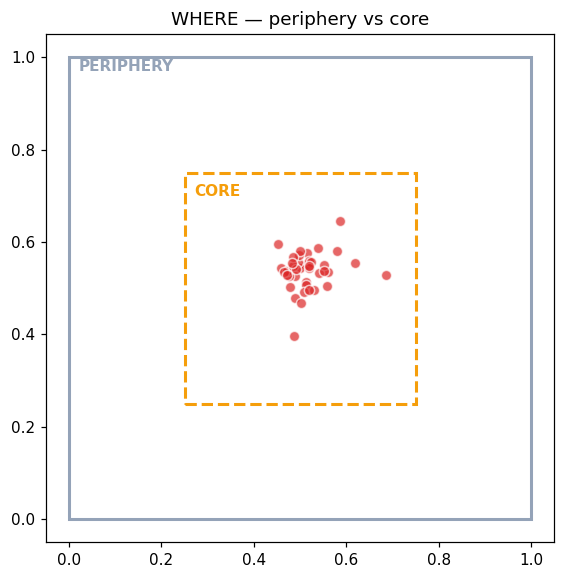

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
m = 0.25
ax.add_patch(plt.Rectangle((0, 0), 1, 1, fill=False, lw=2, edgecolor="#94a3b8"))
ax.add_patch(plt.Rectangle((m, m), 1 - 2 * m, 1 - 2 * m, fill=False, lw=2,
                           edgecolor="#f59e0b", linestyle="--"))
xs, ys = zip(*points) if points else ([], [])
ax.scatter(xs, ys, s=45, c="#dc2626", alpha=0.7, edgecolors="white")
ax.text(m + 0.02, 1 - m - 0.05, "CORE", color="#f59e0b", weight="bold")
ax.text(0.02, 0.97, "PERIPHERY", color="#94a3b8", weight="bold")
ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05); ax.set_aspect("equal")
ax.set_title("WHERE — periphery vs core")
plt.show()

**Read that plot honestly — and notice the result above: every single detection lands in the CORE.** That is not a finding about a field, it is an artefact of photography. People centre their subject when they take a picture, so every box centre sits near the middle of the frame. A `breach=True` verdict here means nothing about a plantation.

The positions are box centres *inside a photo*,
so today the verdict means "edge vs centre of the frame". It becomes a real
field verdict the moment photos carry GPS coordinates — the logic does not
change, only the coordinate space. That is why the WHERE dimension is described
as ready-and-tested rather than demonstrated.

## Video: why persistence matters

A single frame can lie. The fusion engine can require a detection to survive
across several frames before it counts, which kills one-frame flukes.

In [6]:
from src.pipeline import DamageDetection, BBox

engine.reset()
solid = DamageDetection(label="Helopeltis spp.", bbox=BBox(0.4, 0.4, 0.6, 0.6), confidence=0.91)
blip  = DamageDetection(label="Helopeltis spp.", bbox=BBox(0.1, 0.1, 0.2, 0.2), confidence=0.88)

for i in range(5):
    frame = [solid] + ([blip] if i == 0 else [])      # the blip appears once
    stable = engine.push_frame(frame, "new_flush", window=5)

print(f"detections seen across 5 frames : 2 distinct")
print(f"stable after the sliding window : {len(stable)}")
for obs in stable:
    print(" ", obs.insect, obs.position)
print("\nThe single-frame blip was dropped.")

detections seen across 5 frames : 2 distinct
stable after the sliding window : 1
  Helopeltis spp. (0.5, 0.5)

The single-frame blip was dropped.


## What this system is, and what it is not

**It is:** three honest, small models whose numbers were measured on sets that
could contradict them — two of them wired into one record a person can act on,
the third a separate reading on the insect.

**It is not:**

- A field system. Every image it has ever seen came from the internet.
- A pest *detector* in the sense of finding a bug in a wide photo. The insect
  model classifies a photo that already contains one, large and centred.
- Certain. The insect model is confidently wrong about 1 in 9 same-region
  mirids, and the damage detector cannot distinguish Helopeltis damage from
  another pest's damage.
- One system yet. Two entry points that a grower would have to use separately.

**The one thing it would need next:** real plantation photos. Every limit above
traces back to that, and no amount of public data substitutes for it.